# Member 5: Common Evaluation and Integrated Analysis

This walkthrough compares existing trained Snake checkpoints, including Member 4's PPO. Read `README.md` for setup and `member5_report.md` for the full analysis. The implementation is split into Python files so that the notebook remains easy to follow.

The default run loads included formal results and verifies the saved models. It performs no training. This is Member 5's analysis package; the full group submission must also include Members 1-4's methods and the human presentation.

## 1. Install dependencies

Run the following cell if your selected Python environment needs the packages. Restart the kernel after installation if necessary.

In [ ]:
%pip install -r requirements.txt

## 2. Choose what to run

Keep the four flags below false to inspect the included completed evaluation. Set `RUN_SMOKE=True` for a separate 70-game pipeline check. Set `RUN_EVALUATION=True` to repeat all 5,400 common test games; the subsequent analysis then uses that new run. `RUN_ANALYSIS=True` regenerates analysis from the selected formal results without replaying games.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

TRAIN_MODEL = False
RUN_SMOKE = False
RUN_EVALUATION = False
RUN_ANALYSIS = False

here = Path.cwd().resolve()
candidates = [here, here / "member5", here / "Snake" / "member5"]
PACKAGE_DIR = next((p for p in candidates if (p / "LATEST_RUNS.json").is_file()), None)
assert PACKAGE_DIR is not None, "Open this notebook from Snake/member5 in the complete repository."
PROJECT_DIR = PACKAGE_DIR.parent
sys.path.insert(0, str(PACKAGE_DIR))
from member5_unified_evaluation import run_benchmark
from member5_analysis import run_analysis, verify_saved_checkpoints

assert TRAIN_MODEL is False, "This notebook evaluates saved models; it does not train."
included = json.loads((PACKAGE_DIR / "LATEST_RUNS.json").read_text())
evaluation_dir = PACKAGE_DIR / included["evaluation"]
analysis_dir = PACKAGE_DIR / included["analysis"]
print("PPO configuration: clip=0.2, fixed before common evaluation")
print("Included formal evaluation:", included["evaluation"])


PPO configuration: clip=0.2, fixed before common evaluation
Included formal evaluation: results/evaluation/20261025T094915_718765Z


## 3. Verify the delivered checkpoints

The following cell loads all 25 learned checkpoints, checks their seed and condition labels, and verifies repeatable frozen inference. It does not select new checkpoints or train any model.

In [2]:
checkpoint_inventory = verify_saved_checkpoints(PROJECT_DIR)
assert len(checkpoint_inventory) == 25 and checkpoint_inventory["loaded"].all()
display(checkpoint_inventory)
print("All 25 checkpoints loaded. Inference is repeatable and model parameters are unchanged.")

All 25 checkpoints loaded. Inference is repeatable and model parameters are unchanged.


,method,training_seed,loaded,greedy_action,selected_steps,full_training_budget
0,AC,7,True,left,5000,50000
1,AC,42,True,left,20000,50000
2,AC,2026,True,right,5000,50000
3,AC,31415,True,left,10000,50000
4,AC,27182,True,right,20000,50000
5,BC + AC,7,True,left,50000,50000
6,BC + AC,42,True,right,35000,50000
7,BC + AC,2026,True,right,40000,50000
8,BC + AC,31415,True,right,40000,50000
9,BC + AC,27182,True,right,25000,50000


## 4. Optional evaluation and analysis

Common test seeds are 1,200,000-1,200,199. Every learned method has five training seeds and 200 games per model. Random and Teacher each receive one 200-game batch. All methods use the same 8 x 8 game, target length 8 and 300-step limit.

In [3]:
if RUN_SMOKE:
    smoke_result = run_benchmark(project_dir=PROJECT_DIR, mode="smoke")
    assert len(smoke_result["episodes"]) == 70
    print("Smoke output checks the pipeline; it is not final ranking evidence.")
if RUN_EVALUATION:
    new_evaluation = run_benchmark(project_dir=PROJECT_DIR, mode="evaluation")
    evaluation_dir = new_evaluation["result_dir"]
if RUN_ANALYSIS or RUN_EVALUATION:
    new_analysis = run_analysis(result_dir=evaluation_dir, project_dir=PROJECT_DIR)
    analysis_dir = new_analysis["result_dir"]

protocol = json.loads((evaluation_dir / "protocol.json").read_text())
analysis_manifest = json.loads((analysis_dir / "manifest.json").read_text())
figure_dir = PACKAGE_DIR / "figures" / "analysis" / analysis_dir.name
decision_dir = PACKAGE_DIR / analysis_manifest["decision_result_dir"]
decision_figure_dir = PACKAGE_DIR / "figures" / "decisions" / decision_dir.name
episodes = pd.read_csv(evaluation_dir / "episodes.csv")
assert len(episodes) == 5400 and protocol["train_model"] is False
print("Loaded", len(episodes), "formal common-evaluation episodes.")

Loaded 5400 formal common-evaluation episodes.


## 5. Overall delivered-model comparison

PPO uses 500,000 training steps; AC/BC + AC use 50,000 and DQN/DDQN 210,000. BC + AC additionally uses 100 demonstration episodes. These results compare delivered trained outcomes, rather than intrinsic algorithm quality at equal cost. Error bars describe variation across training seeds; baselines have no training replicates.

,method,score_mean,score_training_seed_sd,success_rate,timeout_rate,budget_steps,extra_teacher_episodes
0,Random,0.220,NaN,0.000,0.000,0,0
1,Teacher,7.000,NaN,1.000,0.000,0,0
2,AC,0.129,0.043,0.000,0.000,50000,0
3,BC + AC,1.714,0.292,0.008,0.403,50000,100
4,DQN,5.455,0.221,0.398,0.038,210000,0
5,Double DQN,5.683,0.132,0.473,0.025,210000,0
6,PPO,1.979,0.434,0.038,0.795,500000,0


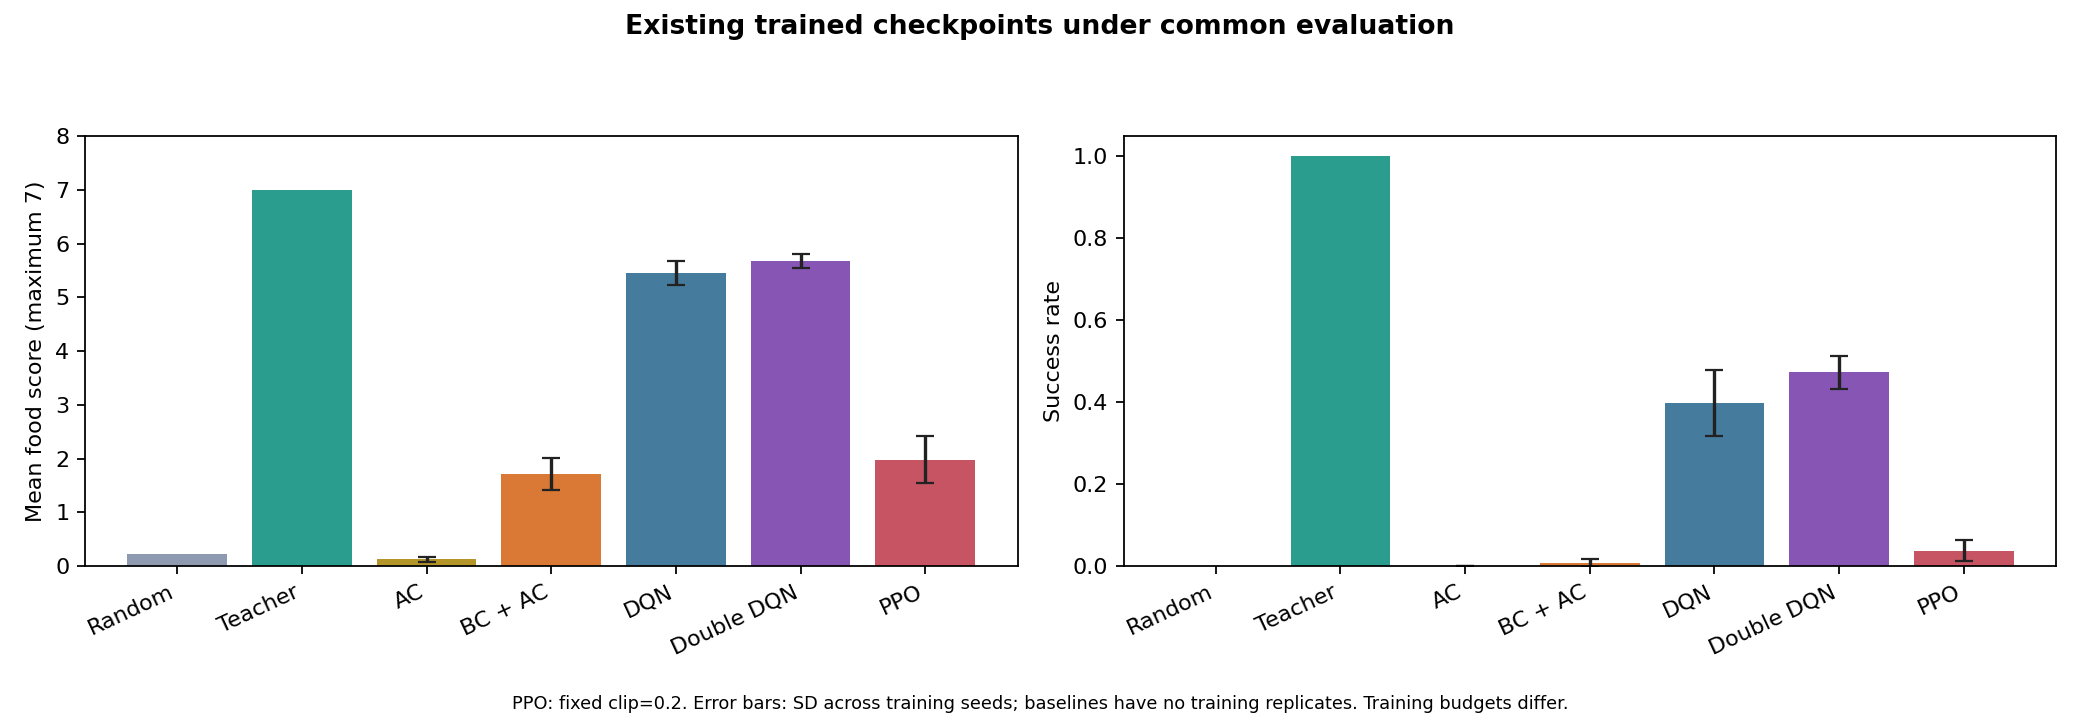

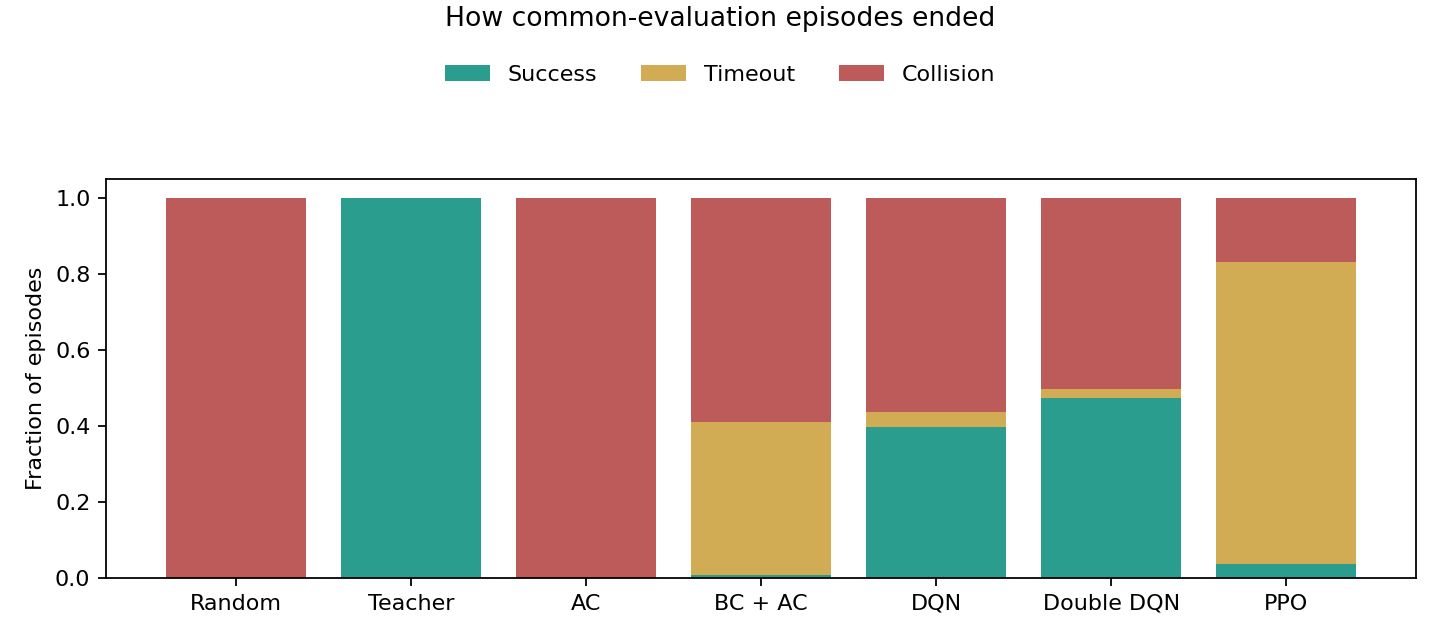

In [4]:
summary = pd.read_csv(evaluation_dir / "summary.csv")
display(summary[["method", "score_mean", "score_training_seed_sd", "success_rate", "timeout_rate", "budget_steps", "extra_teacher_episodes"]].round(3))
display(Image(filename=str(figure_dir / "performance.png")))
display(Image(filename=str(figure_dir / "episode_outcomes.png")))

## 6. Does BC help? Does Double DQN improve on DQN?

The same common test data support both comparisons, paired by training seed. Paired t-tests use Holm adjustment across the two comparisons. They assume approximately normal seed-level differences; the five-seed sample is small. Bootstrap intervals are descriptive, not strong guarantees.

,comparison,n_training_seeds,mean_score_difference,difference_seed_sd,positive_seeds,negative_seeds,t_statistic,p_value,bootstrap_95_low,bootstrap_95_high,p_holm
0,BC + AC minus AC,5,1.585,0.3302,5,0,10.7350,0.0004,1.325,1.815,0.0009
1,Double DQN minus DQN,5,0.228,0.3289,4,1,1.5499,0.1961,-0.023,0.479,0.1961


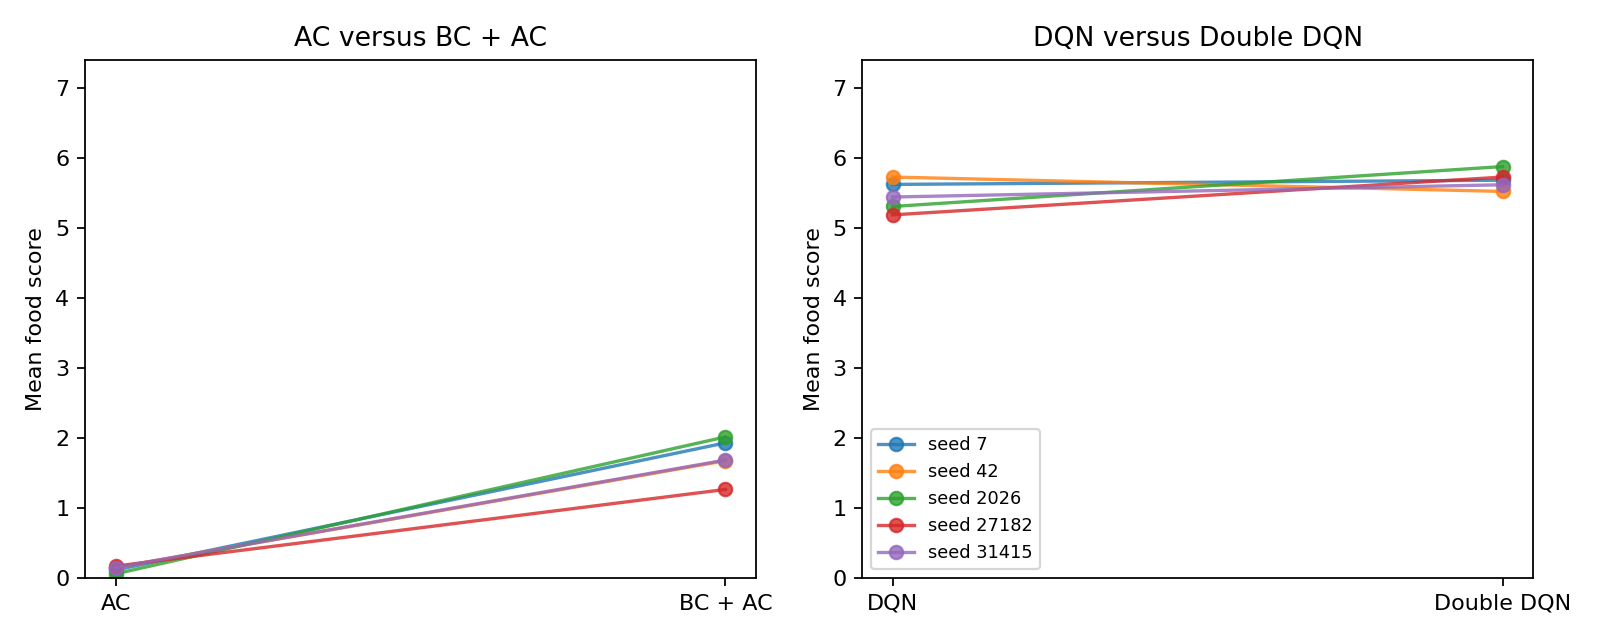

In [5]:
paired = pd.read_csv(analysis_dir / "paired_statistics.csv")
display(paired.round(4))
display(Image(filename=str(figure_dir / "paired_comparisons.png")))

## 7. Learning histories and gameplay during training

These are the original validation histories. Validation seed sets and episode counts differ across members; the three family panels also have different x-axis ranges. The BC + AC point at zero RL steps is after BC warm-up, whose demonstration cost is additional.

The animation belongs to Member 2's BC-assisted Actor-Critic. It shows Initial, After BC, AC midpoint and Best validation on one fixed game seed. Its score changes from zero to one; later stages still fail to complete the task. It is not a PPO training-progress claim.

Historical validation curves provide context; the common final test supports the overall comparison.


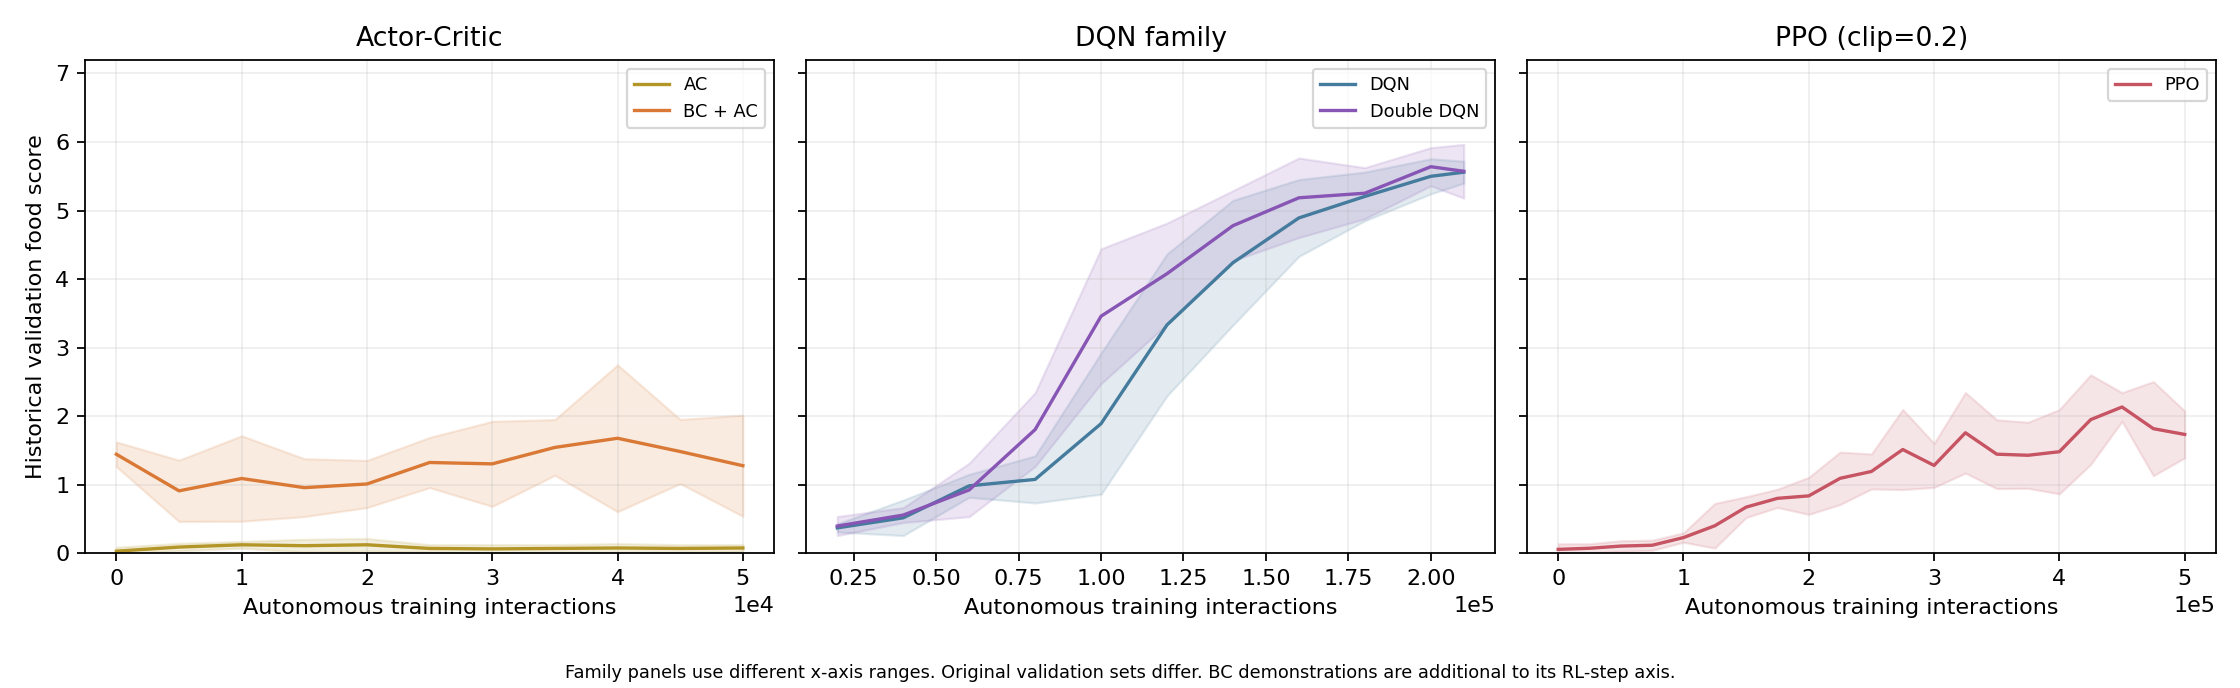

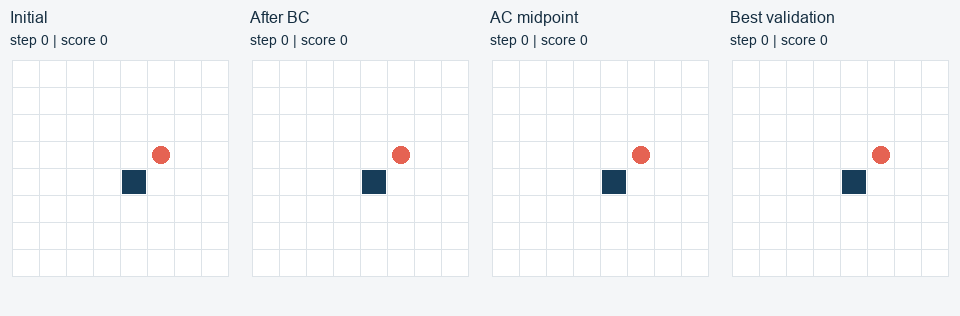

In [6]:
display(Image(filename=str(figure_dir / "learning_curves.png")))
display(Image(filename=str(figure_dir / "training_progress.gif")))
print("Historical validation curves provide context; the common final test supports the overall comparison.")

## 8. PPO's original clipping experiment

Member 4's separate clipping study uses test seeds 2,950,000-2,950,199. Its scores are not pooled with the common test scores. This study does not change the prespecified clip=0.2 choice in our overall table.

In [7]:
display(pd.read_csv(analysis_dir / "ppo_original_clip_study.csv").round(3))

,clip,score_mean,score_seed_sd,success_rate
0,0.1,2.603,0.523,0.099
1,0.2,2.085,0.432,0.048
2,0.3,2.258,0.465,0.024


## 9. Fixed-state decisions

All five learned methods use their seed-42 checkpoints on the same four valid 8 x 8 states. "Clear" means no collision on the next step only. These are qualitative probes, not an overall ranking. Actor probabilities and Q values have different units.

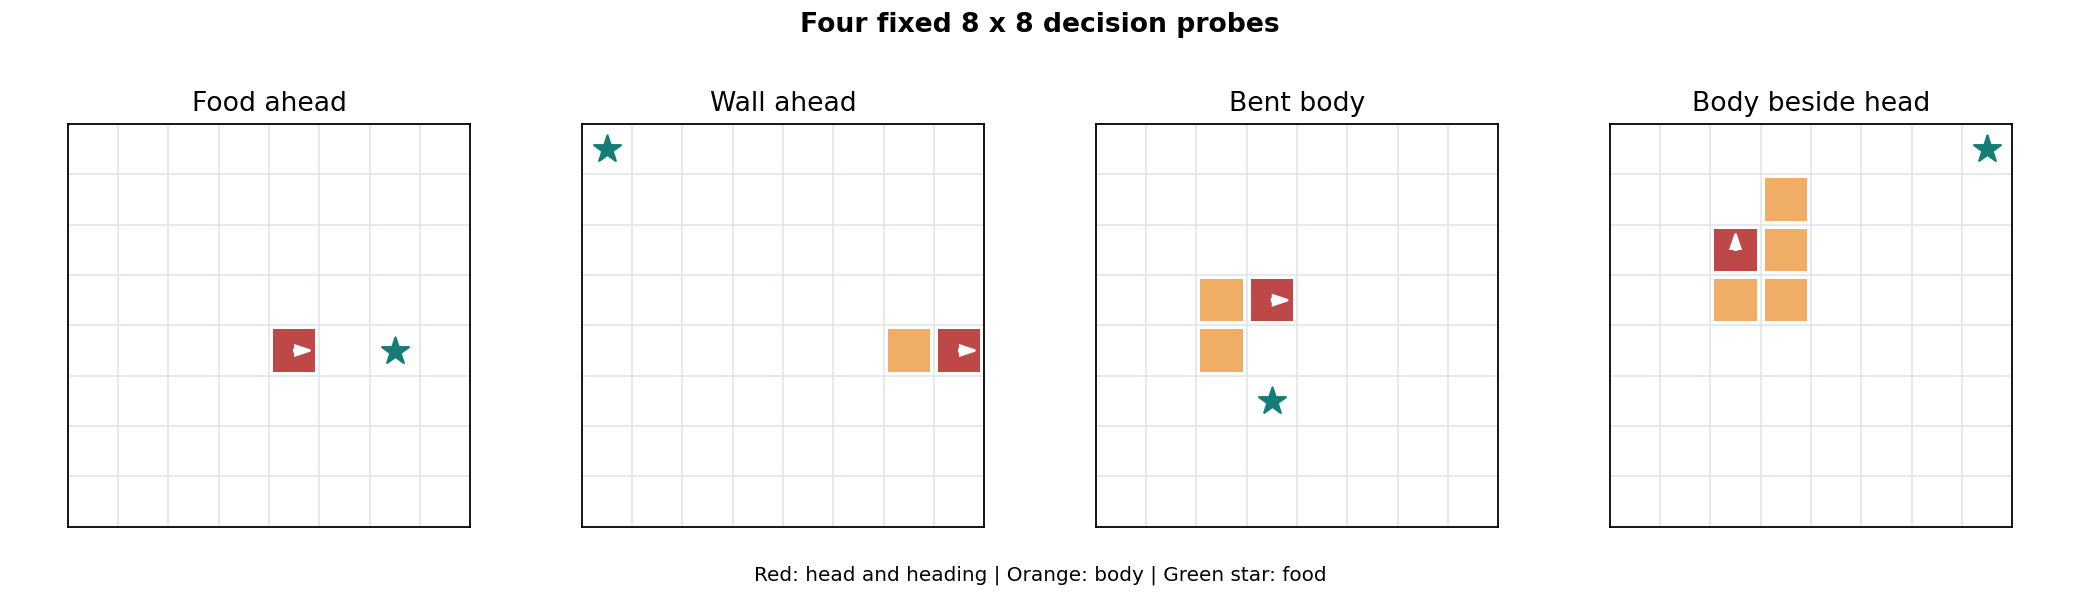

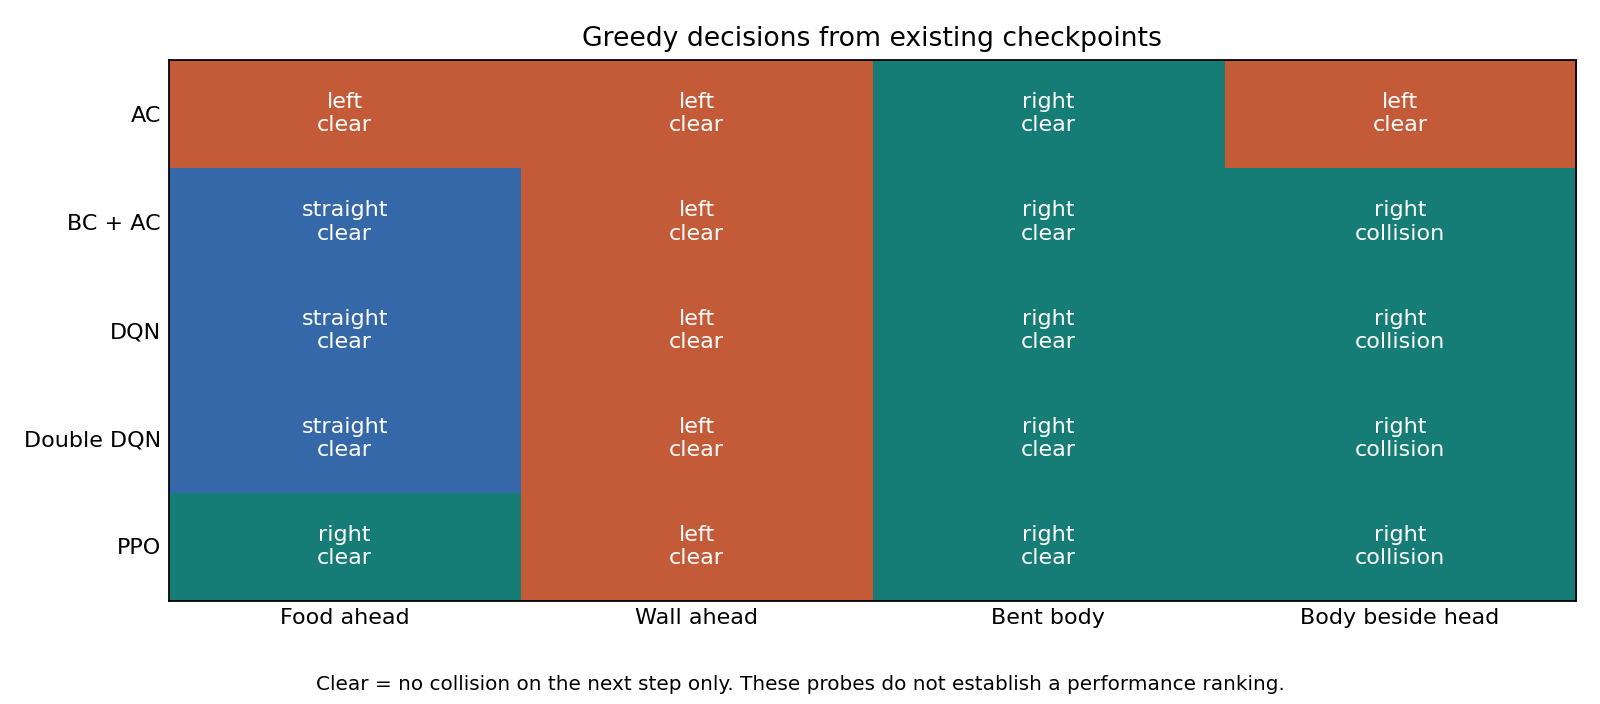

In [8]:
decision_report = json.loads((decision_dir / "decisions.json").read_text())
assert decision_report["inspection_scope"]["model_count"] == 5
display(Image(filename=str(decision_figure_dir / "fixed_states.png")))
display(Image(filename=str(decision_figure_dir / "selected_actions.png")))

## 10. Read the conclusions and integrate the group report

The complete English discussion, exact statistics, provenance and limitations are in `member5_report.md` and the timestamped analysis report. Merge this analysis with Members 1-4's methods and actual contribution record into one runnable final group notebook, and prepare the required human presentation.

Original group members supplied the game, algorithms, trained weights, histories and animation. OpenAI Codex assisted evaluation, analysis, documentation and verification. Students remain responsible for understanding and presenting the work.

In [9]:
best = summary[~summary["method"].isin(["Random", "Teacher"])].sort_values("score_mean", ascending=False).iloc[0]
print(f"Highest observed learned-agent mean score: {best['method']} ({best['score_mean']:.3f}).")
print("Compare existing trained outcomes; training budgets and other training choices differ.")
print("Detailed analysis:", str(analysis_dir.relative_to(PACKAGE_DIR) / "report.md"))

Highest observed learned-agent mean score: Double DQN (5.683).
Compare existing trained outcomes; training budgets and other training choices differ.
Detailed analysis: results/analysis/20261025T095930_719652Z/report.md
